# Fraud Detection & Risk Assessment System
## Phase 1: Exploratory Data Analysis & Defensive Data Validation

**Author**: Yaman Chahar  
**Project**: Fraud Detection & Risk Assessment System Using Machine Learning  
**Dataset**: [ULB Machine Learning Group - Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

---
### Objectives of this Notebook
1. **Defensive Validation**: Validate dataset schema, data types, missing values, and column constraints.
2. **Class Imbalance Exploration**: Quantify the extreme class imbalance and understand why standard classification accuracy fails.
3. **Duplicate & Outlier Investigation**: Audit duplicate records and heavy-tailed distributions without mutating raw data.
4. **Feature Behavior**: Inspect `Time`, `Amount`, and anonymized PCA features (`V1`–`V28`) across legitimate vs fraudulent transactions.
5. **Architectural Foundations for Phase 2**: Establish evidence-based recommendations for preprocessing, scaling, and validation protocols.

### 1. Environment & Library Setup
We import our core data analysis libraries along with our project configuration (`src.config`) and validation utilities (`src.data_validation`).

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path when running from notebooks/
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data_validation import load_and_validate_dataset, check_dataset_exists

# Set plot styling for clean, professional reports
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

print(f"Project root resolved: {PROJECT_ROOT}")
print(f"Target dataset path: {config.DATASET_PATH}")

Project root resolved: C:\Users\Yaman Chahar\Desktop\Fraud_Detection
Target dataset path: C:\Users\Yaman Chahar\Desktop\Fraud_Detection\data\creditcard.csv


### 2. Defensive Dataset Loading & Schema Validation
In financial risk systems, silently accepting corrupt or missing inputs can cause catastrophic prediction errors. We validate:
- File existence and size.
- All 31 canonical columns (`Time`, `V1`–`V28`, `Amount`, `Class`).
- Numeric data types and absence of NaNs / infinities.

In [2]:
try:
    df, validation_meta = load_and_validate_dataset(config.DATASET_PATH)
    print("\u2705 Dataset loaded and validated successfully!")
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"Schema Valid: {validation_meta['schema']['valid']}")
    print(f"Total Missing Values: {validation_meta['integrity']['total_nulls']}")
    print(f"Total Infinite Values: {validation_meta['integrity']['total_infinities']}")
except FileNotFoundError as e:
    print("\u274c DATASET NOT FOUND ERROR:")
    print(e)
    df = None

✅ Dataset loaded and validated successfully!
Shape: 284,807 rows x 31 columns
Schema Valid: True
Total Missing Values: 0
Total Infinite Values: 0


### 3. Duplicate Records Investigation
In credit card transactions, identical rows can arise from:
1. Rapid automated retries / card network re-transmissions.
2. The anonymization/PCA process compressing timestamp/location granularity.

> **Key Rule**: We audit duplicates without automatically modifying or dropping records from the raw dataset, keeping our evaluation protocol uncorrupted.

In [3]:
if df is not None:
    dup_info = validation_meta['duplicates']
    print(f"Total Rows: {dup_info['total_rows']:,}")
    print(f"Duplicate Rows: {dup_info['num_duplicate_rows']:,} ({dup_info['duplicate_percentage']} %)")
    print("Duplicate breakdown by class:")
    for cls, cnt in dup_info['duplicate_class_distribution'].items():
        label = 'Fraudulent' if cls == 1 else 'Legitimate'
        print(f"  - Class {cls} ({label}): {cnt:,} records")
else:
    print("Awaiting dataset placement to compute duplicate records.")

Total Rows: 284,807
Duplicate Rows: 1,081 (0.3796 %)
Duplicate breakdown by class:
  - Class 0 (Legitimate): 1,062 records
  - Class 1 (Fraudulent): 19 records


### 4. Class Imbalance Analysis & The Failure of Accuracy

#### Why Raw Accuracy is Deceptive
Suppose a dataset has 99.83% legitimate transactions and 0.17% fraudulent transactions.
A **trivial / naive classifier** that predicts every transaction is legitimate will achieve **99.83% accuracy**.

However:
- **Fraud Detected (True Positives)**: 0%
- **Recall for Fraud**: 0.00
- **Financial Loss**: 100% of fraud goes through undetected.

Therefore, in fraud detection:
- **Precision** (avoiding false alarms) and **Recall** (catching fraud) are primary.
- **PR-AUC (Precision-Recall Area Under Curve)** and **Cost-Sensitive Class Weighting** are far more informative than Accuracy or standard ROC-AUC.

Total Transactions: 284,807
Legitimate (Class 0): 284,315 (99.8273 %)
Fraudulent (Class 1): 492 (0.1727 %)
Imbalance Ratio: ~577.88:1 (Legitimate : Fraudulent)


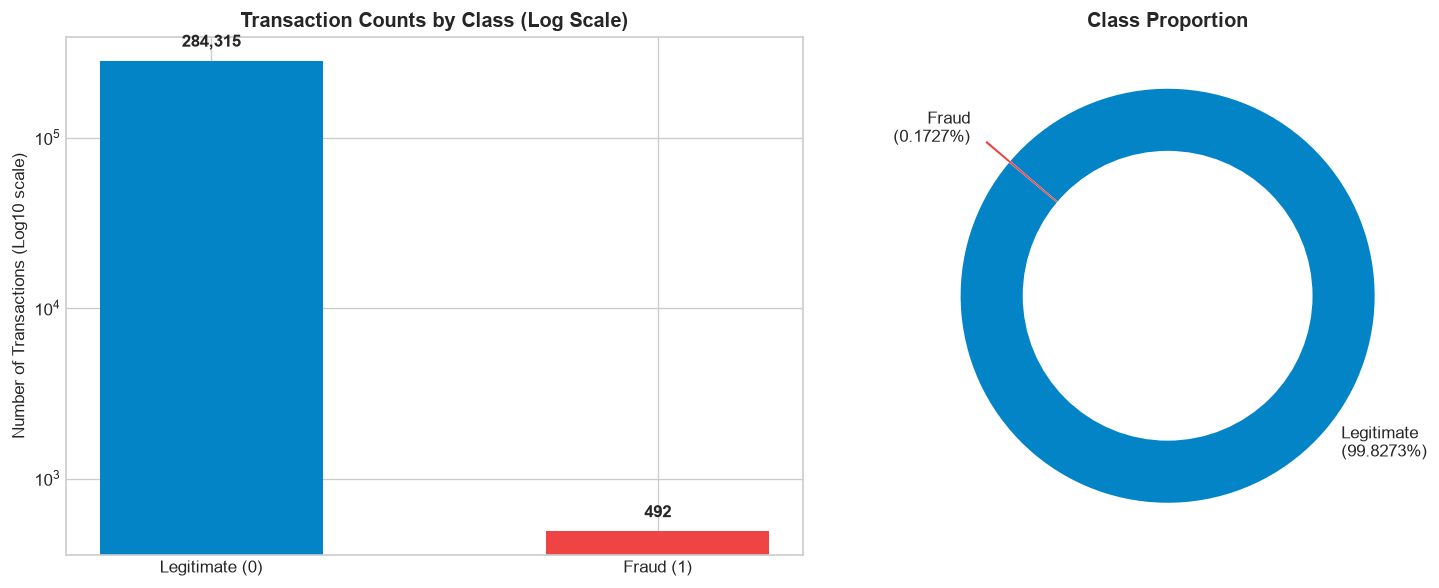

In [4]:
if df is not None:
    dist = validation_meta['class_distribution']
    print(f"Total Transactions: {dist['total_transactions']:,}")
    print(f"Legitimate (Class 0): {dist['legitimate_count']:,} ({dist['legitimate_percentage']} %)")
    print(f"Fraudulent (Class 1): {dist['fraudulent_count']:,} ({dist['fraudulent_percentage']} %)")
    print(f"Imbalance Ratio: ~{dist['imbalance_ratio']}:1 (Legitimate : Fraudulent)")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    
    # Bar Chart with Log Scale for Clarity
    bars = ax1.bar(['Legitimate (0)', 'Fraud (1)'], [dist['legitimate_count'], dist['fraudulent_count']], color=['#0284C7', '#EF4444'], width=0.5)
    ax1.set_yscale('log')
    ax1.set_title('Transaction Counts by Class (Log Scale)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Number of Transactions (Log10 scale)')
    for bar in bars:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval * 1.15, f"{yval:,}", ha='center', va='bottom', fontweight='bold')

    # Donut Chart for Percentage Breakdown
    labels = [f"Legitimate\n({dist['legitimate_percentage']}%)", f"Fraud\n({dist['fraudulent_percentage']}%)"]
    ax2.pie([dist['legitimate_count'], dist['fraudulent_count']], labels=labels, colors=['#0284C7', '#EF4444'], explode=(0, 0.15), autopct=None, startangle=140)
    centre_circle = plt.Circle((0,0), 0.70, fc='white')
    ax2.add_artist(centre_circle)
    ax2.set_title('Class Proportion', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("Awaiting dataset placement to render class distribution.")

### 5. Transaction Amount Distribution
We examine whether transaction amount alone is a reliable indicator of fraud.

--- Legitimate Transactions Amount Stats ---
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

--- Fraudulent Transactions Amount Stats ---
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


C:\Users\Yaman Chahar\AppData\Local\Temp\ipykernel_7612\268069157.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


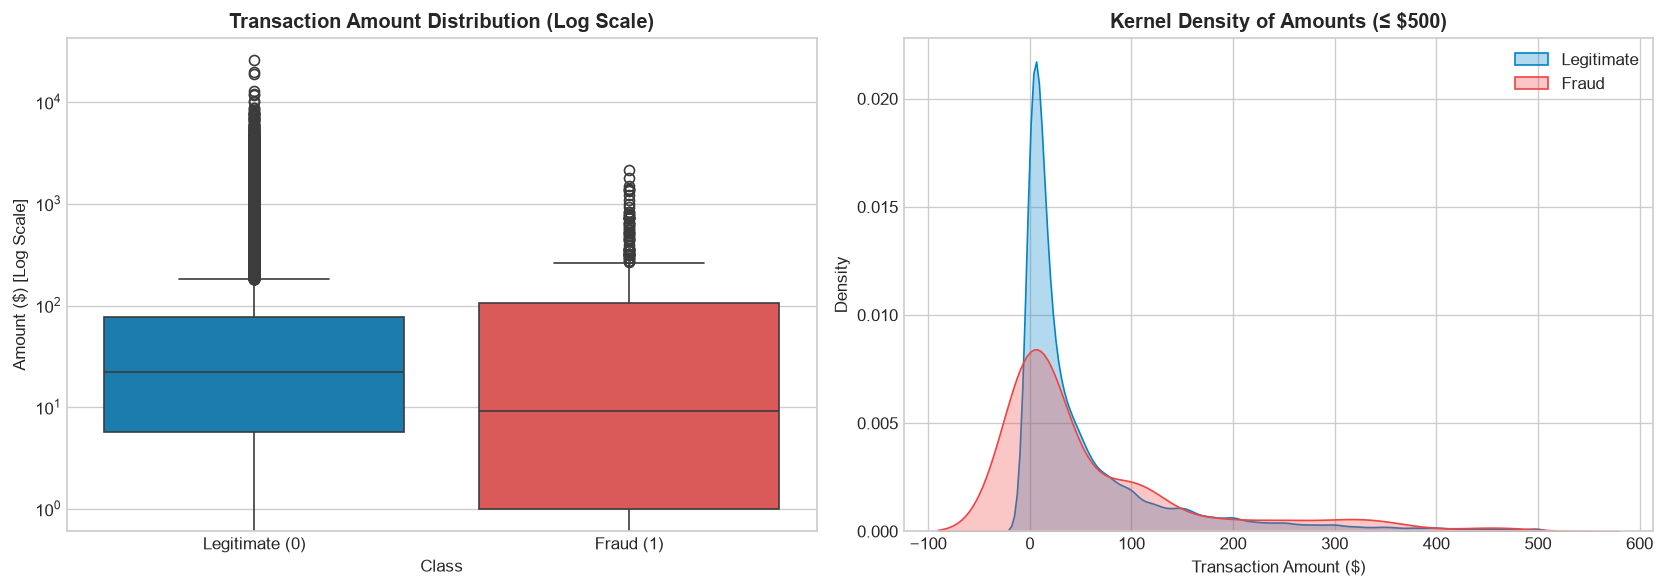

In [5]:
if df is not None:
    legit_amt = df[df['Class'] == 0]['Amount']
    fraud_amt = df[df['Class'] == 1]['Amount']

    print("--- Legitimate Transactions Amount Stats ---")
    print(legit_amt.describe())
    print("\n--- Fraudulent Transactions Amount Stats ---")
    print(fraud_amt.describe())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Boxplot of Amount with log scale
    sns.boxplot(data=df, x='Class', y='Amount', ax=ax1, palette=['#0284C7', '#EF4444'], hue='Class', legend=False)
    ax1.set_yscale('log')
    ax1.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
    ax1.set_title('Transaction Amount Distribution (Log Scale)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Amount ($) [Log Scale]')

    # Distribution comparison below $500
    sns.kdeplot(legit_amt[legit_amt <= 500], ax=ax2, label='Legitimate', color='#0284C7', fill=True, alpha=0.3)
    sns.kdeplot(fraud_amt[fraud_amt <= 500], ax=ax2, label='Fraud', color='#EF4444', fill=True, alpha=0.3)
    ax2.set_title('Kernel Density of Amounts (\u2264 $500)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Transaction Amount ($)')
    ax2.set_ylabel('Density')
    ax2.legend()

    plt.tight_layout()
    plt.show()
else:
    print("Awaiting dataset placement to analyze Amount distributions.")

### 6. Transaction Time Distribution
The `Time` column measures elapsed seconds from the start of the recording period (~48 hours / 2 days total).
We convert seconds to hour-of-day to identify temporal patterns in fraudulent versus legitimate activity.

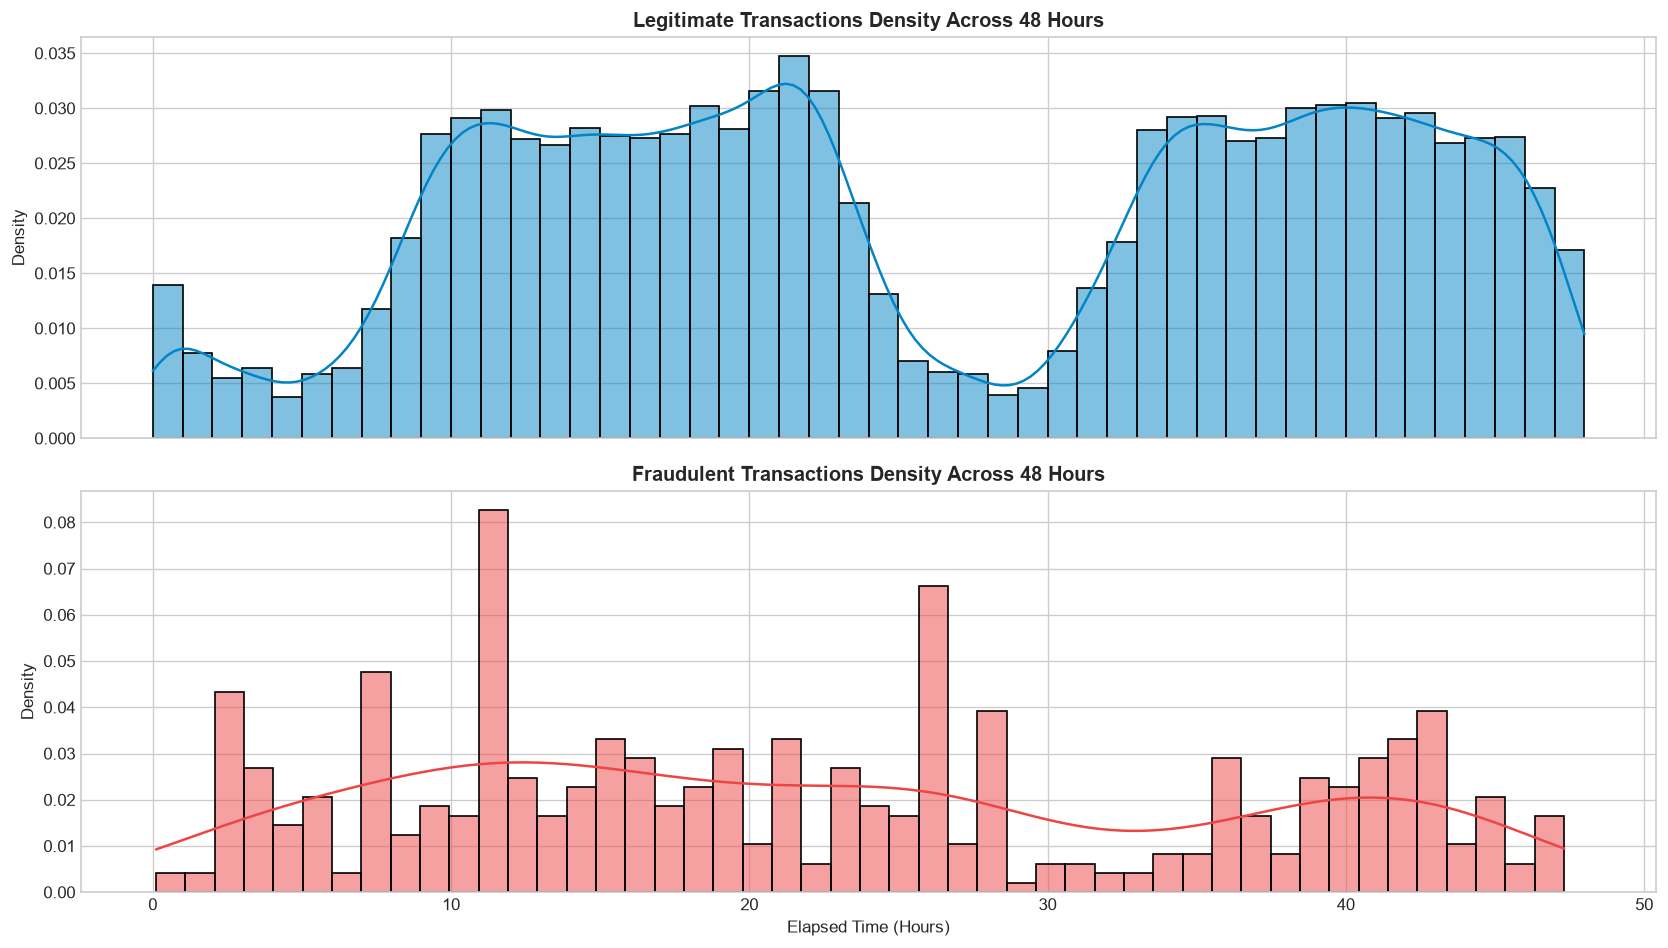

In [6]:
if df is not None:
    # Convert seconds to hours across the 48-hour recording window
    time_hours = df['Time'] / 3600.0
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    
    sns.histplot(time_hours[df['Class'] == 0], bins=48, ax=ax1, color='#0284C7', stat='density', kde=True)
    ax1.set_title('Legitimate Transactions Density Across 48 Hours', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Density')
    
    sns.histplot(time_hours[df['Class'] == 1], bins=48, ax=ax2, color='#EF4444', stat='density', kde=True)
    ax2.set_title('Fraudulent Transactions Density Across 48 Hours', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Elapsed Time (Hours)')
    ax2.set_ylabel('Density')
    
    plt.tight_layout()
    plt.show()
else:
    print("Awaiting dataset placement to analyze Time distributions.")

### 7. PCA Features Divergence & Correlation Analysis
Features `V1` through `V28` are anonymized principal components resulting from PCA.
We examine which components show the strongest linear and rank correlation with the fraud target (`Class`).

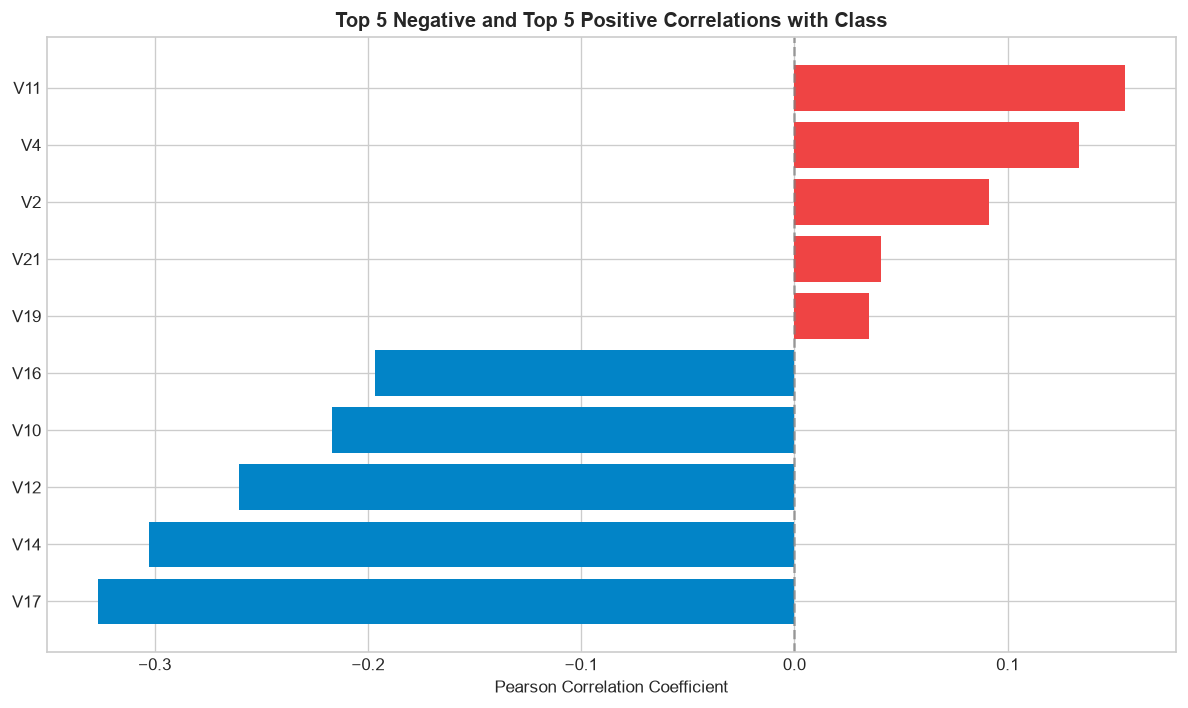

Top correlated features with Class:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


In [7]:
if df is not None:
    correlations = df.corr()['Class'].drop('Class').sort_values()
    
    top_neg = correlations.head(5)
    top_pos = correlations.tail(5)
    top_features = pd.concat([top_neg, top_pos])

    plt.figure(figsize=(10, 6))
    colors = ['#EF4444' if x > 0 else '#0284C7' for x in top_features.values]
    bars = plt.barh(top_features.index, top_features.values, color=colors)
    plt.title('Top 5 Negative and Top 5 Positive Correlations with Class', fontsize=12, fontweight='bold')
    plt.xlabel('Pearson Correlation Coefficient')
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    print("Top correlated features with Class:")
    print(top_features)
else:
    print("Awaiting dataset placement for correlation analysis.")

### 8. Architectural Implications for Phase 2 (Preprocessing)

Based on data validation and statistical characteristics:
1. **Strict Leakage Prevention**: Preprocessing scalers (`RobustScaler` / `StandardScaler`) must be fit **only** on training folds, never on validation or test partitions.
2. **Feature Scale Disparities**: PCA features (`V1`–`V28`) already have mean close to 0 and variance near 1. In contrast, `Time` and `Amount` span radically different scales (`Amount` is heavily right-skewed with extreme outliers). `RobustScaler` is ideal for `Amount` to resist outlier distortion.
3. **Stratified Partitioning**: Because fraud represents < 0.2% of data, standard random splitting risks catastrophic class imbalance variance between folds. Stratified K-Fold and stratified train/test splits are mandatory.
4. **No Resampling in Validation/Test**: Resampling algorithms (e.g. SMOTE) must operate strictly within training pipelines, keeping validation and test evaluation grounded in the real transaction distribution.